# Retail Sales: Data Profile & Quality Checks
Executable companion to the **KPI Dictionary** and **Data Quality Contract**.

- **Dataset:** `retail_sales_dataset.csv` (one row per transaction)
- **Decision owner:** Retail Sales Manager
- **What this notebook does:** runs 20+ checks across completeness, uniqueness, validity, consistency and freshness; grades each against the contract thresholds (PASS / WARN / FAIL); exports `dq_results.csv`; and computes the KPIs only from rows that pass validation.

Change `DATA_PATH` or `AS_OF` in the next cell to re-run on a new extract.

In [1]:
import pandas as pd, numpy as np, re, os
from pathlib import Path

DATA_PATH = os.environ.get("DQ_DATA_PATH") or next(p for p in [
    "/mnt/user-data/uploads/retail_sales_dataset.csv",
    "retail_sales_dataset.csv"] if Path(p).exists())
print("Profiling:", DATA_PATH)
AS_OF = pd.Timestamp.today().normalize()      # the date freshness is measured against

# ---- Contract: reference lists and the expected schema ----
EXPECTED_COLS = ["Transaction ID","Date","Customer ID","Gender","Age",
                 "Product Category","Quantity","Price per Unit","Total Amount"]
ALLOWED = {"Gender": {"Male","Female"},
           "Product Category": {"Beauty","Clothing","Electronics"}}
AGE_MIN, AGE_MAX = 18, 100
DATE_FORMAT = "%d-%m-%Y"
FRESHNESS_SLA_DAYS = 1     # daily refresh => newest transaction should be <= 1 day old
pd.set_option("display.width", 140)

Profiling: /mnt/user-data/uploads/retail_sales_dataset.csv


## 1. Load as text first
Everything is read as strings so that bad values are *detected* by the checks, not silently coerced by the loader.

In [2]:
raw = pd.read_csv(DATA_PATH, dtype=str, keep_default_na=False, na_values=[""])
raw.columns = [x.strip() for x in raw.columns]
print(f"{len(raw):,} rows x {raw.shape[1]} columns")
raw.head()

1,000 rows x 9 columns


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,24-11-2023,CUST001,Male,34,Beauty,3,50,150
1,2,27-02-2023,CUST002,Female,26,Clothing,2,500,1000
2,3,13-01-2023,CUST003,Male,50,Electronics,1,30,30
3,4,21-05-2023,CUST004,Male,37,Clothing,1,500,500
4,5,06-05-2023,CUST005,Male,30,Beauty,2,50,100


## 2. Parse into typed columns
Parsing failures become `NaT`/`NaN` and are counted by the validity checks.

In [3]:
df = raw.copy()
df["_date"]   = pd.to_datetime(df["Date"], format=DATE_FORMAT, errors="coerce")
for col in ["Age","Quantity","Price per Unit","Total Amount"]:
    df["_"+col] = pd.to_numeric(df[col], errors="coerce")
df["_tid"] = pd.to_numeric(df["Transaction ID"], errors="coerce")
df.dtypes

Transaction ID                 str
Date                           str
Customer ID                    str
Gender                         str
Age                            str
Product Category               str
Quantity                       str
Price per Unit                 str
Total Amount                   str
_date               datetime64[us]
_Age                         int64
_Quantity                    int64
_Price per Unit              int64
_Total Amount                int64
_tid                         int64
dtype: object

## 3. Check framework
Each check returns the **failing row count** and its **failure rate**, then is graded against a *warn* and *fail* threshold (as a % of rows). Thresholds mirror the contract (`data_quality_contract.md`).

In [4]:
RESULTS = []
N = len(df)

def grade(rate, warn, fail):
    if rate >= fail: return "FAIL"
    if rate > warn:  return "WARN"
    return "PASS"

def check(cid, dimension, rule, bad_mask, warn=0.0, fail=0.5, severity="High", note=""):
    bad = int(bad_mask.sum()); rate = 100*bad/N
    RESULTS.append(dict(check_id=cid, dimension=dimension, rule=rule, failing_rows=bad,
                        failure_rate_pct=round(rate,3), warn_above_pct=warn, fail_at_pct=fail,
                        status=grade(rate,warn,fail), severity=severity, note=note))

def check_value(cid, dimension, rule, observed, ok, status_if_bad="FAIL", severity="High", note=""):
    RESULTS.append(dict(check_id=cid, dimension=dimension, rule=rule, failing_rows=np.nan,
                        failure_rate_pct=np.nan, warn_above_pct=np.nan, fail_at_pct=np.nan,
                        status="PASS" if ok else status_if_bad, severity=severity,
                        note=f"observed: {observed}" + (f" | {note}" if note else "")))

### 3.1 Completeness: are required fields populated?

In [5]:
missing_cols = [x for x in EXPECTED_COLS if x not in raw.columns]
check_value("CMP-00","Completeness","All 9 expected columns present", missing_cols or "none missing", not missing_cols)

for i, col in enumerate(EXPECTED_COLS, start=1):
    blank = raw[col].isna() | (raw[col].astype(str).str.strip() == "")
    check(f"CMP-{i:02d}","Completeness",f"{col} is not null or blank", blank, warn=0.0, fail=1.0)

### 3.2 Uniqueness: is the grain respected?

In [6]:
dup_tid = df["Transaction ID"].duplicated(keep=False) & df["Transaction ID"].notna()
check("UNQ-01","Uniqueness","Transaction ID is unique (grain = 1 row per transaction)", dup_tid, warn=0.0, fail=0.1)

full_dup = df[EXPECTED_COLS].duplicated(keep=False)
check("UNQ-02","Uniqueness","No fully duplicated rows", full_dup, warn=0.0, fail=0.1)

repeat_cust = df["Customer ID"].duplicated(keep=False)
check("UNQ-03","Uniqueness","Customer ID repeats across transactions (informational)", repeat_cust,
      warn=100, fail=101, severity="Info",
      note="0 repeats means each customer appears once, so repeat-purchase KPIs cannot be built from this extract")

### 3.3 Validity: do values fall in the allowed domain?

In [7]:
check("VAL-01","Validity","Transaction ID is a positive integer", ~(df["_tid"].fillna(0) > 0), warn=0.0, fail=0.5)
check("VAL-02","Validity",f"Date parses as {DATE_FORMAT} (dd-mm-yyyy)", df["_date"].isna(), warn=0.0, fail=0.5)
check("VAL-03","Validity","Date is not in the future", df["_date"] > AS_OF, warn=0.0, fail=0.1)
check("VAL-04","Validity","Customer ID matches CUST + digits", ~df["Customer ID"].fillna("").str.match(r"^CUST\d+$"), warn=0.0, fail=0.5)
check("VAL-05","Validity","Gender is Male or Female", ~df["Gender"].isin(ALLOWED["Gender"]), warn=0.0, fail=1.0)
check("VAL-06","Validity",f"Age is a whole number {AGE_MIN}-{AGE_MAX}",
      ~(df["_Age"].between(AGE_MIN, AGE_MAX) & (df["_Age"] % 1 == 0)), warn=0.0, fail=0.5)
check("VAL-07","Validity","Product Category is in the approved list", ~df["Product Category"].isin(ALLOWED["Product Category"]), warn=0.0, fail=0.5)
check("VAL-08","Validity","Quantity is a whole number > 0", ~((df["_Quantity"] > 0) & (df["_Quantity"] % 1 == 0)), warn=0.0, fail=0.5)
check("VAL-09","Validity","Price per Unit > 0", ~(df["_Price per Unit"] > 0), warn=0.0, fail=0.5)
check("VAL-10","Validity","Total Amount >= 0", ~(df["_Total Amount"] >= 0), warn=0.0, fail=0.5)

### 3.4 Consistency: do fields agree with each other and over time?

In [8]:
calc = df["_Quantity"] * df["_Price per Unit"]
check("CON-01","Consistency","Total Amount = Quantity x Price per Unit", (calc != df["_Total Amount"]) | calc.isna(), warn=0.0, fail=0.5)

# Same product category should keep a stable price list
price_sets = df.groupby("Product Category")["_Price per Unit"].nunique()
check_value("CON-02","Consistency","Price points per category (informational: price list looks tiered, not one price)",
            price_sets.to_dict(), True, severity="Info")

ids = df["_tid"].dropna().astype(int).sort_values()
gaps = (ids.diff().dropna() != 1).sum()
check_value("CON-03","Consistency","Transaction IDs are contiguous (no missing IDs)", f"{gaps} gaps", gaps == 0, status_if_bad="WARN", severity="Medium")

check("CON-04","Consistency","Text columns have no leading/trailing spaces or case drift",
      (df["Gender"] != df["Gender"].str.strip().str.title()) |
      (df["Product Category"] != df["Product Category"].str.strip().str.title()), warn=0.0, fail=0.5, severity="Medium")

# Partial period: last month much smaller than the typical month
by_month = df.dropna(subset=["_date"]).groupby(df["_date"].dt.to_period("M")).size()
typical = by_month.iloc[:-1].median()
last_ratio = by_month.iloc[-1] / typical
check_value("CON-05","Consistency","Latest month is a complete period (rows >= 50% of typical month)",
            f"{by_month.index[-1]}: {by_month.iloc[-1]} rows vs typical {typical:.0f}", last_ratio >= 0.5,
            status_if_bad="WARN", severity="Medium",
            note="a partial month distorts MoM growth, so the KPI dictionary excludes it")

### 3.5 Freshness: is the data recent enough for its refresh cadence?

In [9]:
newest = df.loc[df["_date"] <= AS_OF, "_date"].max()   # ignore future-dated rows (caught by VAL-03)
age_days = (AS_OF - newest).days
check_value("FRS-01","Freshness",f"Newest transaction is <= {FRESHNESS_SLA_DAYS} day old",
            f"newest={newest.date()}, as-of={AS_OF.date()}, lag={age_days} days", age_days <= FRESHNESS_SLA_DAYS,
            note="this file is a historical snapshot, so FAIL is expected; the check proves the monitor would catch a stalled feed")

span_days = (newest - df["_date"].min()).days
check_value("FRS-02","Freshness","Data covers >= 12 months (needed for seasonality / MoM)", f"{span_days} days", span_days >= 365, status_if_bad="WARN", severity="Low")

## 4. Quality scorecard

In [10]:
res = pd.DataFrame(RESULTS)
order = {"FAIL":0,"WARN":1,"PASS":2}
display(res.sort_values(["dimension","check_id"]).style.map(
    lambda v: {"FAIL":"background:#f8c9c4","WARN":"background:#fdeeb5","PASS":"background:#d3ecd5"}.get(v,""), subset=["status"]))
print(res["status"].value_counts().to_string())
print("\nBy dimension:")
print(pd.crosstab(res["dimension"], res["status"]))

,check_id,dimension,rule,failing_rows,failure_rate_pct,warn_above_pct,fail_at_pct,status,severity,note
0,CMP-00,Completeness,All 9 expected columns present,nan,nan,nan,nan,PASS,High,observed: none missing
1,CMP-01,Completeness,Transaction ID is not null or blank,0.000000,0.000000,0.000000,1.000000,PASS,High,
2,CMP-02,Completeness,Date is not null or blank,0.000000,0.000000,0.000000,1.000000,PASS,High,
3,CMP-03,Completeness,Customer ID is not null or blank,0.000000,0.000000,0.000000,1.000000,PASS,High,
4,CMP-04,Completeness,Gender is not null or blank,0.000000,0.000000,0.000000,1.000000,PASS,High,
5,CMP-05,Completeness,Age is not null or blank,0.000000,0.000000,0.000000,1.000000,PASS,High,
6,CMP-06,Completeness,Product Category is not null or blank,0.000000,0.000000,0.000000,1.000000,PASS,High,
7,CMP-07,Completeness,Quantity is not null or blank,0.000000,0.000000,0.000000,1.000000,PASS,High,
8,CMP-08,Completeness,Price per Unit is not null or blank,0.000000,0.000000,0.000000,1.000000,PASS,High,
9,CMP-09,Completeness,Total Amount is not null or blank,0.000000,0.000000,0.000000,1.000000,PASS,High,


status
PASS    28
WARN     1
FAIL     1

By dimension:
status        FAIL  PASS  WARN
dimension                     
Completeness     0    10     0
Consistency      0     4     1
Freshness        1     1     0
Uniqueness       0     3     0
Validity         0    10     0


## 5. Release decision
Per the contract: any **FAIL on a High-severity check blocks the daily KPI publish** and triggers escalation. A WARN publishes with a banner.

In [11]:
blockers = res[(res.status=="FAIL") & (res.severity=="High")]
non_fresh = blockers[blockers.dimension!="Freshness"]
print("Row-level quality (completeness, uniqueness, validity, consistency):",
      "CLEAN" if non_fresh.empty else "FAILURES -> " + ", ".join(non_fresh.check_id))
print("Freshness:", "OK" if blockers[blockers.dimension=="Freshness"].empty else "STALE -> " +
      ", ".join(blockers[blockers.dimension=="Freshness"].check_id))
print("\nDecision:", "PUBLISH" if blockers.empty else "BLOCK PUBLISH and escalate (see contract section 5)")

Row-level quality (completeness, uniqueness, validity, consistency): CLEAN
Freshness: STALE -> FRS-01

Decision: BLOCK PUBLISH and escalate (see contract section 5)


In [12]:
res.to_csv("dq_results.csv", index=False)
print("saved dq_results.csv")

saved dq_results.csv


## 6. KPI computation (valid rows only)
Applies each KPI's filter from the dictionary. Values here should match the formulas in the workbook's `kpi_dictionary` and `kpi_breakdowns` sheets.

In [13]:
valid = df[
    df["_tid"].notna() & df["_date"].notna() & df["Customer ID"].notna() &
    df["Product Category"].isin(ALLOWED["Product Category"]) &
    (df["_Quantity"] > 0) & df["_Total Amount"].notna() & df["_Age"].between(AGE_MIN, AGE_MAX)
].copy()
print(f"{len(valid):,} of {N:,} rows pass the KPI validity filter")

bands = [17,24,34,44,54,64,200]; labels = ["18-24","25-34","35-44","45-54","55-64","65+"]
valid["age_group"] = pd.cut(valid["_Age"], bands, labels=labels)
valid["month"] = valid["_date"].dt.to_period("M")

kpis = {
 "K1 Total Sales Amount": valid["_Total Amount"].sum(),
 "K2 Total Transactions": valid["_tid"].nunique(),
 "K3 Units Sold": valid["_Quantity"].sum(),
 "K4 Average Order Value": valid["_Total Amount"].sum() / valid["_tid"].nunique(),
 "K5 Total Customers": valid["Customer ID"].nunique(),
 "K9 Avg Units per Transaction": valid["_Quantity"].sum() / valid["_tid"].nunique(),
}
pd.Series(kpis).round(2).to_frame("value")

1,000 of 1,000 rows pass the KPI validity filter

,value
K1 Total Sales Amount,456000.00
K2 Total Transactions,1000.00
K3 Units Sold,2514.00
K4 Average Order Value,456.00
K5 Total Customers,1000.00
K9 Avg Units per Transaction,2.51


In [14]:
cat = valid.groupby("Product Category")["_Total Amount"].sum().sort_values(ascending=False).to_frame("sales")
cat["share_pct"] = (100*cat["sales"]/cat["sales"].sum()).round(2)
cat   # K6 and K10

,sales,share_pct
Product Category,,
Electronics,156905,34.41
Clothing,155580,34.12
Beauty,143515,31.47


In [15]:
valid.groupby("age_group", observed=True)["_Total Amount"].sum().to_frame("sales")   # K7

,sales
age_group,
18-24,74650
25-34,97090
35-44,96835
45-54,97235
55-64,90190


In [16]:
# K8: monthly sales + MoM. The latest month is partial, so MoM is suppressed for it.
m = valid.groupby("month").agg(sales=("_Total Amount","sum"), transactions=("_tid","nunique"))
m["mom_pct"] = (100*m["sales"].pct_change()).round(2)
m["complete_month"] = m["transactions"] >= 0.5*m["transactions"].iloc[:-1].median()
m.loc[~m["complete_month"], "mom_pct"] = np.nan
m

,sales,transactions,mom_pct,complete_month
month,,,,
2023-01,35450,76,NaN,True
2023-02,44060,85,24.29,True
2023-03,28990,73,-34.20,True
2023-04,33870,86,16.83,True
2023-05,53150,105,56.92,True
2023-06,36715,77,-30.92,True
2023-07,35465,72,-3.40,True
2023-08,36960,94,4.22,True
2023-09,23620,65,-36.09,True


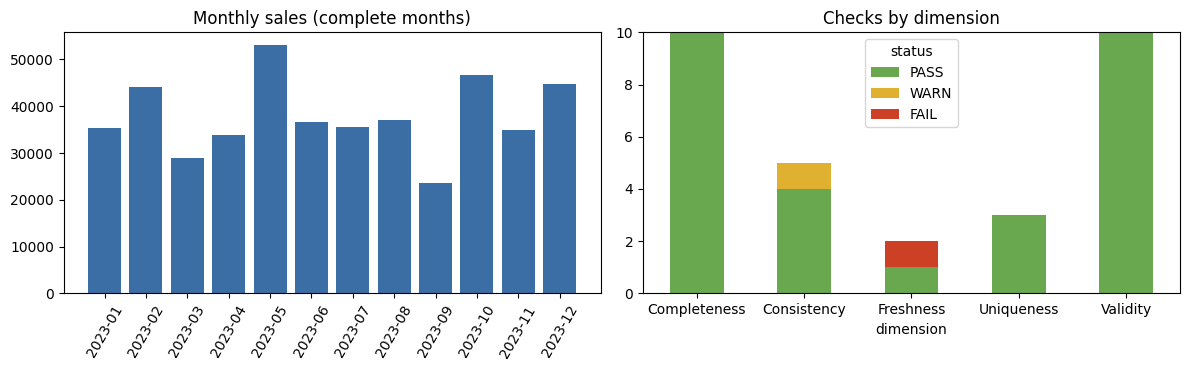

In [17]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1,2, figsize=(12,3.8))
mm = m[m.complete_month]
ax[0].bar(mm.index.astype(str), mm["sales"], color="#3b6ea5"); ax[0].set_title("Monthly sales (complete months)")
ax[0].tick_params(axis="x", rotation=60)
res.groupby(["dimension","status"]).size().unstack(fill_value=0).reindex(columns=["PASS","WARN","FAIL"], fill_value=0)\
   .plot.bar(stacked=True, ax=ax[1], color=["#6aa84f","#e0b030","#cc4125"]); ax[1].set_title("Checks by dimension")
ax[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

## 7. Findings
1. **Row-level quality is clean:** no nulls, no duplicate IDs, every `Total Amount` equals `Quantity x Price per Unit`, all categories and ages valid.
2. **Freshness fails by design:** the newest record is 1 Jan 2024. A daily-refresh KPI feed fed by this file would be flagged stale.
3. **Latest month (Jan 2024) holds 2 rows:** MoM growth for it would be meaningless, so it is excluded.
4. **Customer ID is unique per row:** `Total Customers` equals `Total Transactions`; repeat-purchase and retention KPIs are not possible from this extract.
5. **The original data dictionary did not match this dataset** (it described `order_id`, `city`, `discount_pct` ...); a corrected dictionary is in the workbook.